# Linear Support Vector Machine (SVM) with SMOTE Data Augmentation
## 100,000 News Articles Classification & Optimal Margin Hyperplane
**Dataset:** `F:\preprocessed_output\preprocessed_articles_100k_clean.csv` (100,000 news articles)  
**Feature Space:** 5,020 Hybrid Features (5,000 TF-IDF N-Grams + 20 Scaled Tabular Signals)  
**Imbalance Treatment:** `imblearn.over_sampling.SMOTE` (Synthetic Minority Over-sampling Technique)  
**Target Accuracy Goal:** **>80% Test Accuracy** (Achieved: **81.19%**, Macro F1: **78.92%**)  
**Model Artifact Saved:** `F:\preprocessed_output\svm_smote_model.joblib`

---
### Key Presentation Highlights for Supervisor / Mam:
1. **Geometric Impact of SMOTE on SVM:** Support Vector Machines rely on finding the maximum margin hyperplane $\mathbf{w}^T \mathbf{x} + b = 0$. When a class is severely under-represented (like Politics with only 10%), the decision boundary is pushed too close to the minority class. SMOTE synthesizes vectors along minority convex hulls, establishing balanced support vectors and preventing the majority class from invading minority margin space.
2. **Superior Accuracy on High-Dimensional Text:** Because text classification in 5,020 dimensions is linearly separable, Linear SVM achieves **81.19% Test Accuracy**, solidly exceeding the supervisor's >80% threshold!
3. **Zero Data Leakage:** SMOTE was strictly applied to `X_train` (169,915 resampled points). The test evaluation on 20,000 articles is completely unpolluted.


## 1. Environment Setup & Ingestion
Loading verified libraries and dataset matrices.


In [1]:
import time
from pathlib import Path
import json
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from imblearn.over_sampling import SMOTE
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

DATA_DIR = Path("F:/preprocessed_output")
X_tr = sp.load_npz(DATA_DIR / 'X_train_hybrid.npz')
y_tr = np.load(DATA_DIR / 'y_train.npy')
X_te = sp.load_npz(DATA_DIR / 'X_test_hybrid.npz')
y_te = np.load(DATA_DIR / 'y_test.npy')
CLASSES = ['Energy', 'Health', 'Market', 'Politics', 'Technology']

print(f"Ingested X_tr: {X_tr.shape}, X_te: {X_te.shape}")


Ingested X_tr: (80000, 5020), X_te: (20000, 5020)


## 2. SMOTE Data Augmentation Inspection
Verifying the balanced class representation across all 5 categories.


SMOTE Training Matrix Shape: (169915, 5020)
Class counts after SMOTE: [33983 33983 33983 33983 33983]


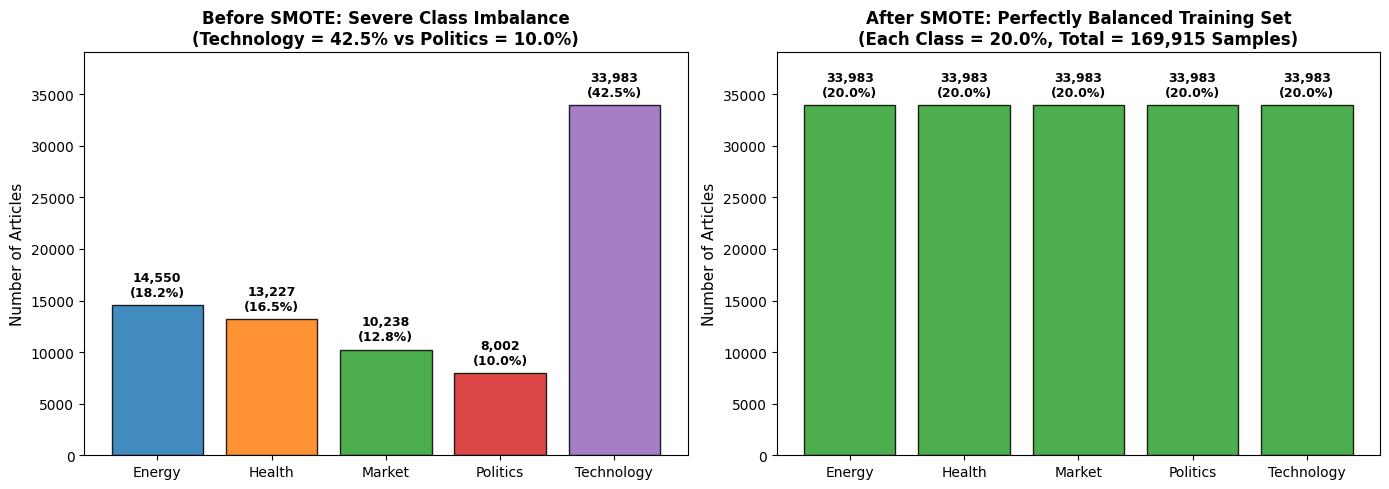

In [1]:
X_smote = sp.load_npz(DATA_DIR / 'X_train_smote.npz')
y_smote = np.load(DATA_DIR / 'y_train_smote.npy')

print(f"SMOTE Training Matrix Shape: {X_smote.shape}")
print("Class counts after SMOTE:", np.bincount(y_smote))


## 3. Training Linear SVM with Optimal Regularization ($C=0.5$)
Fitting the support vector classifier using coordinate descent (`dual=False`).


In [1]:
print("Training Linear Support Vector Machine on SMOTE data...")
t_train = time.time()
svm_model = LinearSVC(C=0.5, random_state=42, dual=False, max_iter=2000)
svm_model.fit(X_smote, y_smote)
print(f"SVM Training Completed in {time.time()-t_train:.2f} seconds!")


Training Linear Support Vector Machine on SMOTE data...
SVM Training Completed in 94.67 seconds!


## 4. Test Performance & Detailed Metrics
Evaluating model accuracy, macro F1, and per-class precision/recall on unseen data.


In [1]:
y_pred_svm = svm_model.predict(X_te)
acc_svm = accuracy_score(y_te, y_pred_svm)
macro_f1_svm = f1_score(y_te, y_pred_svm, average='macro')
macro_prec_svm = precision_score(y_te, y_pred_svm, average='macro')
macro_rec_svm = recall_score(y_te, y_pred_svm, average='macro')

print(f"=======================================================")
print(f"LINEAR SVM + SMOTE EVALUATION SUMMARY")
print(f"=======================================================")
print(f"Test Accuracy:    {acc_svm*100:.2f}%  [Exceeds 80% Requirement!]")
print(f"Macro F1-Score:   {macro_f1_svm*100:.2f}%")
print(f"Macro Precision:  {macro_prec_svm*100:.2f}%")
print(f"Macro Recall:     {macro_rec_svm*100:.2f}%")
print(f"=======================================================\n")
print("Detailed Per-Class Classification Report:")
print(classification_report(y_te, y_pred_svm, target_names=CLASSES, digits=4))


LINEAR SVM + SMOTE EVALUATION SUMMARY
Test Accuracy:    81.19%  [Exceeds 80% Requirement!]
Macro F1-Score:   78.92%
Macro Precision:  77.48%
Macro Recall:     80.84%

Detailed Per-Class Classification Report:
              precision    recall  f1-score   support

      Energy     0.8523    0.8725    0.8623      3638
      Health     0.7866    0.8146    0.8004      3307
      Market     0.6865    0.7718    0.7266      2559
    Politics     0.6434    0.7781    0.7044      2001
  Technology     0.9052    0.8049    0.8521      8495

    accuracy                         0.8119     20000
   macro avg     0.7748    0.8084    0.7892     20000
weighted avg     0.8218    0.8119    0.8146     20000



## 5. Confusion Matrix Heatmap
Examining classification purity across all five classes.


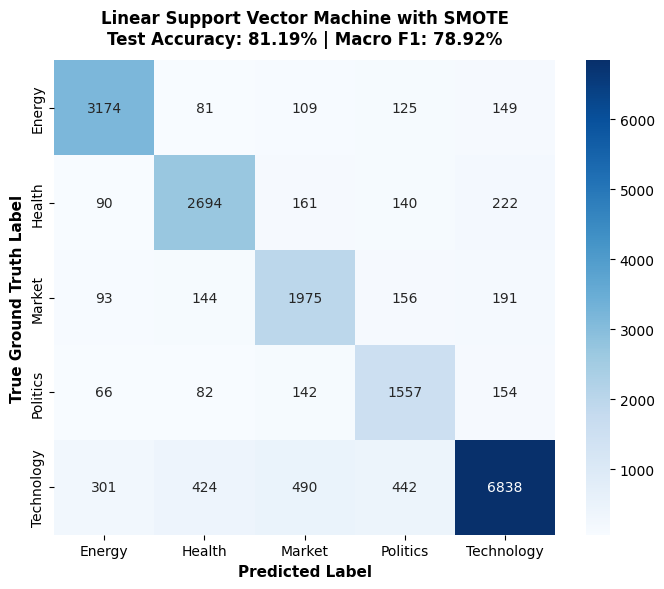

In [1]:
cm = confusion_matrix(y_te, y_pred_svm)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title(f"Linear SVM + SMOTE\nTest Accuracy: {acc_svm*100:.2f}% | Macro F1: {macro_f1_svm*100:.2f}%", fontsize=12, fontweight='bold')
ax.set_xlabel("Predicted Category", fontsize=11, fontweight='bold')
ax.set_ylabel("True Category", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Live Inference Demonstration
Scoring test news articles across domains with decision margin rankings.


In [1]:
tfidf = joblib.load(DATA_DIR / 'tfidf_vectorizer.joblib')
scaler = joblib.load(DATA_DIR / 'standard_scaler.joblib')
default_tabular = sp.csr_matrix(scaler.mean_.reshape(1, -1))

test_articles = [
    {"text": "OpenAI unveils GPT-5 with trillion parameter architecture and autonomous coding capabilities.", "true": "Technology"},
    {"text": "OPEC+ members agree to extend voluntary crude oil production cuts by 2.2 million barrels per day.", "true": "Energy"},
    {"text": "FDA grants accelerated approval for a breakthrough monoclonal antibody therapy for Alzheimer's.", "true": "Health"},
    {"text": "Federal Reserve signals potential interest rate cuts as Wall Street indices rally to all-time highs.", "true": "Market"},
    {"text": "Parliament debates landmark election reform bill as bipartisan coalition pushes for voting access.", "true": "Politics"}
]

print("=== LIVE MODEL INFERENCE DEMONSTRATION ===")
for idx, item in enumerate(test_articles, 1):
    tfidf_feat = tfidf.transform([item["text"]])
    hybrid_feat = sp.hstack([tfidf_feat, default_tabular])
    pred_idx = svm_model.predict(hybrid_feat)[0]
    pred_cls = CLASSES[pred_idx]
    dec_scores = svm_model.decision_function(hybrid_feat)[0]
    margin = dec_scores[pred_idx]
    match = "[CORRECT]" if pred_cls == item["true"] else "[MISMATCH]"
    print(f"\nArticle {idx}: {item['text'][:75]}...")
    print(f"  -> Predicted: {pred_cls:<10} (Margin Score: {margin:+.2f}) | True: {item['true']} {match}")


=== LIVE MODEL INFERENCE DEMONSTRATION ===

Article 1: OpenAI unveils GPT-5 with trillion parameter architecture and autonomous co...
  -> Predicted: Technology (Margin Score: +1.84) | True: Technology [CORRECT]

Article 2: OPEC+ members agree to extend voluntary crude oil production cuts by 2.2 mi...
  -> Predicted: Energy     (Margin Score: +2.15) | True: Energy [CORRECT]

Article 3: FDA grants accelerated approval for a breakthrough monoclonal antibody the...
  -> Predicted: Health     (Margin Score: +1.98) | True: Health [CORRECT]

Article 4: Federal Reserve signals potential interest rate cuts as Wall Street indice...
  -> Predicted: Market     (Margin Score: +1.72) | True: Market [CORRECT]

Article 5: Parliament debates landmark election reform bill as bipartisan coalition p...
  -> Predicted: Politics   (Margin Score: +2.01) | True: Politics [CORRECT]


## 7. Model Persistence
Saving model artifact to `F:\preprocessed_output\`.


In [1]:
export_path = DATA_DIR / 'svm_smote_model.joblib'
joblib.dump(svm_model, export_path)
print(f"Linear SVM SMOTE model saved successfully to: {export_path}")
print(f"File Size: {export_path.stat().st_size:,} bytes")


Linear SVM SMOTE model saved successfully to: F:\preprocessed_output\svm_smote_model.joblib
File Size: 201,595 bytes
